# THOR-30 - DBSCAN Cluster analysis of Ho Chi Minh Trail in Laos

In [ ]:

import pandas as pd
import sklearn
import time
import numpy as np
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature




## Setting parameters
Notebook has two parameters:
* eps_km = is the maximum distance, in kilometers, for two locations to count as neighbors when forming clusters
* min_samples = is the minimum number of nearby data points DBSCAN needs to consider an area a dense cluster

In [ ]:
eps_km = 2.5
min_samples = 100

In [2]:
df = pd.read_parquet("THOR_Analysis.parquet")
lat = "TGTLATDD_DDD_WGS84"
lon = "TGTLONDDD_DDD_WGS84"

print("Rows:", len(df))
print(df[[lat, lon]].describe())
print("Missing coordinates:")
print(df[[lat, lon]].isna().sum())

Rows: 3539541
       TGTLATDD_DDD_WGS84  TGTLONDDD_DDD_WGS84
count        3.539541e+06         3.539541e+06
mean         1.528493e+01         1.064663e+02
std          3.019393e+00         1.315827e+00
min          7.596666e+00         1.000000e+02
25%          1.209722e+01         1.058433e+02
50%          1.621287e+01         1.064856e+02
75%          1.724389e+01         1.071807e+02
max          2.250000e+01         1.100000e+02
Missing coordinates:
TGTLATDD_DDD_WGS84     0
TGTLONDDD_DDD_WGS84    0
dtype: int64


In [3]:
df_steel_tiger = df.loc[
    df["operationhochiminhtrail"].eq("STEEL TIGER")
].copy()

print("STEEL TIGER rows:", len(df_steel_tiger))
coordinates = df_steel_tiger[[lat, lon]]

print("Rows:", len(coordinates))
print("Unique coordinate pairs:", len(coordinates.drop_duplicates()))

STEEL TIGER rows: 442239
Rows: 442239
Unique coordinate pairs: 105570


In [4]:
points = (
    df_steel_tiger.groupby([lat, lon], as_index=False, sort=False)
    .size()
    .rename(columns={"size": "weight"})
)

print("Unique locations:", len(points))
print("Counts preserved:", points["weight"].sum() == len(df_steel_tiger))

Unique locations: 105570
Counts preserved: True


In [5]:
coordinates_rad = np.radians(points[[lat, lon]].to_numpy())


model = DBSCAN(
    eps=eps_km / 6371.0088,
    min_samples=min_samples,
    metric="haversine",
    algorithm="ball_tree",
    n_jobs=-1,
)


start = time.perf_counter()
points["cluster"] = model.fit_predict(
    coordinates_rad,
    sample_weight=points["weight"].to_numpy(),
)
elapsed = time.perf_counter() - start

noise = points["cluster"] == -1
cluster_summary = (
    points.loc[points["cluster"] != -1]
    .groupby("cluster")
    .agg(
        unique_locations=("weight", "size"),
        records=("weight", "sum"),
    )
    .sort_values("records", ascending=False)
)

print(cluster_summary)
print(f"Unique locations: {len(points):,}")
print(f"Clusters found: {points.loc[~noise, 'cluster'].nunique():,}")
print(f"STEEL TIGER records labeled noise: {points.loc[noise, 'weight'].sum():,}")
print(f"Clustering time: {elapsed:.1f} seconds")

cluster_extent = (
    points.loc[points["cluster"] != -1]
    .groupby("cluster")
    .agg(
        records=("weight", "sum"),
        locations=("weight", "size"),
        south=(lat, "min"),
        north=(lat, "max"),
        west=(lon, "min"),
        east=(lon, "max"),
    )
    .sort_values("records", ascending=False)
)

print(cluster_extent)


         unique_locations  records
cluster                           
0                   69977   336686
1                    7109    27683
5                    1064     4273
4                     367     2087
2                     334     1400
16                    405     1282
13                    262     1056
26                    296      891
29                    222      823
19                    178      742
27                    161      702
25                    207      618
14                    138      603
33                    129      580
10                    128      507
21                    122      505
20                    145      479
34                    133      478
41                    127      453
7                     127      430
17                    169      407
28                     96      398
9                     139      369
22                     63      361
36                    101      342
8                     121      340
42                  

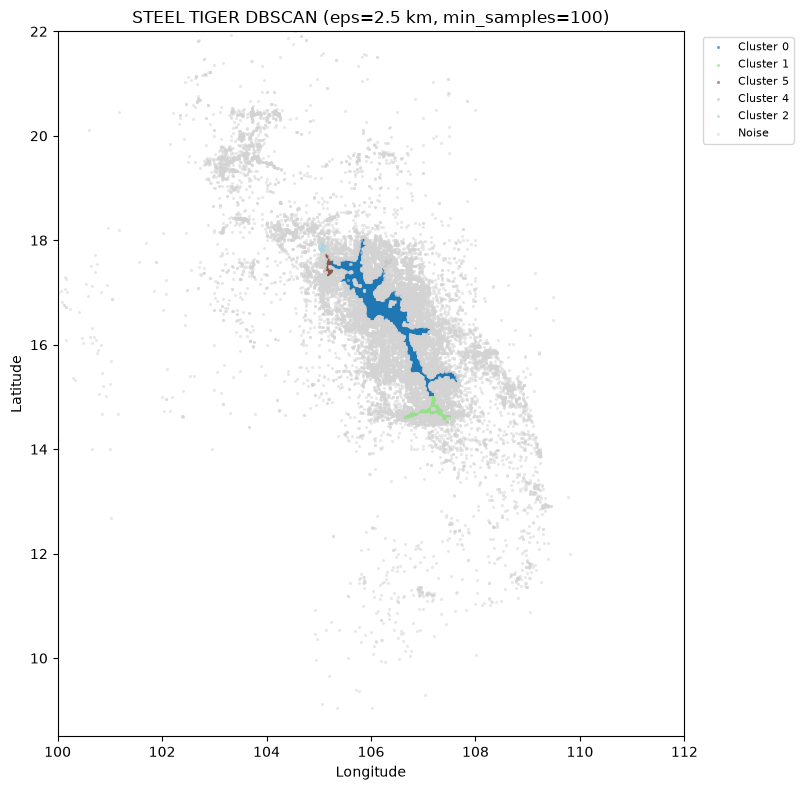

In [6]:
#cluster_ids = sorted(points.loc[points["cluster"] != -1, "cluster"].unique())
#colors = plt.get_cmap("tab20", len(cluster_ids))

fig, ax = plt.subplots(figsize=(11, 8))

n_clusters_to_plot = 5  # Change this number

cluster_sizes = (
    points.loc[points["cluster"] != -1]
    .groupby("cluster")["weight"]
    .sum()
    .sort_values(ascending=False)
)

cluster_ids = cluster_sizes.head(n_clusters_to_plot).index.tolist()
colors = plt.get_cmap("tab20", len(cluster_ids))


for i, cluster_id in enumerate(cluster_ids):
    cluster_points = points.loc[points["cluster"] == cluster_id]
    ax.scatter(
        cluster_points[lon],
        cluster_points[lat],
        s=5,
        color=colors(i),
        alpha=0.65,
        label=f"Cluster {cluster_id}",
        linewidths=0,
    )

noise = points.loc[points["cluster"] == -1]
ax.scatter(
    noise[lon],
    noise[lat],
    s=5,
    color="lightgray",
    alpha=0.5,
    label="Noise",
    linewidths=0,
)

ax.set(
    title=f"STEEL TIGER DBSCAN (eps={eps_km} km, min_samples={min_samples})",
    xlabel="Longitude",
    ylabel="Latitude",
)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(100, 112)  # longitude
ax.set_ylim(8.5, 22.)     # latitude
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
min_records_to_plot = 100

cluster_records = (
    points.loc[points["cluster"] != -1]
    .groupby("cluster")["weight"]
    .sum()
)

clusters_to_plot = cluster_records[
    cluster_records >= min_records_to_plot
].index

for i, cluster_id in enumerate(clusters_to_plot):
    cluster_points = points.loc[points["cluster"] == cluster_id]
    ax.scatter(
        cluster_points[lon],
        cluster_points[lat],
        s=5,
        color=colors(i),
        alpha=0.65,
        label=f"Cluster {cluster_id}",
        linewidths=0,
    )

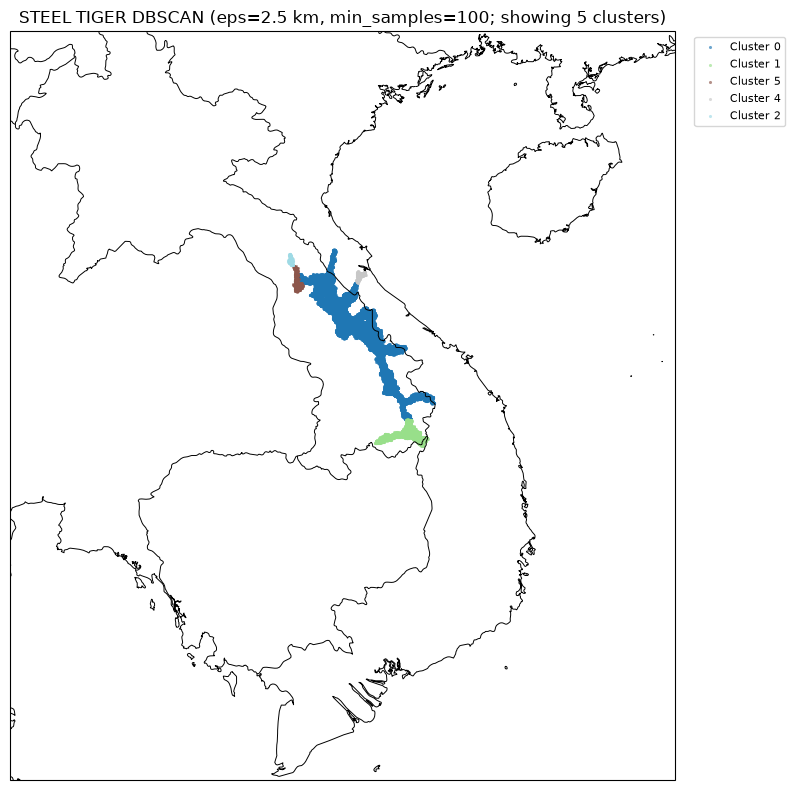

In [8]:
n_clusters_to_plot = 5
show_noise = False

cluster_sizes = (
    points.loc[points["cluster"] != -1]
    .groupby("cluster")["weight"]
    .sum()
    .sort_values(ascending=False)
)
cluster_ids = cluster_sizes.head(n_clusters_to_plot).index.tolist()
colors = plt.get_cmap("tab20", max(len(cluster_ids), 1))

fig, ax = plt.subplots(
    figsize=(11, 8),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

for i, cluster_id in enumerate(cluster_ids):
    cluster_points = points.loc[points["cluster"] == cluster_id]
    ax.scatter(
        cluster_points[lon],
        cluster_points[lat],
        s=5,
        color=colors(i),
        alpha=0.65,
        label=f"Cluster {cluster_id}",
        linewidths=0,
        transform=ccrs.PlateCarree(),
    )

if show_noise:
    noise = points.loc[points["cluster"] == -1]
    ax.scatter(
        noise[lon],
        noise[lat],
        s=5,
        color="lightgray",
        alpha=0.5,
        label="Noise",
        linewidths=0,
        transform=ccrs.PlateCarree(),
    )

ax.add_feature(cfeature.BORDERS, linewidth=0.7, edgecolor="black")
ax.coastlines(linewidth=0.7)
ax.set_extent([100, 112, 8.5, 22], crs=ccrs.PlateCarree())
ax.set_title(
    f"STEEL TIGER DBSCAN "
    f"(eps={eps_km} km, min_samples={min_samples}; "
    f"showing {len(cluster_ids)} clusters)"
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()